# Project purpose on application ML engineering

| Domain / Module | Modeling Approach | Objective / Target | Key Notes & Constraints |
| :--- | :--- | :--- | :--- |
| **Fraud prediction** | Anomaly / integrity detection | Detect data integrity violations | Impossible to model true fraud (no labels, no financial fields). Checks rules like refused > requested, staff_present > total_staff, and departure < arrival. |
| **Service performance** | ✅ Regression / ranking | Predict a Service Health Score | — |
| **Staff analytics** | ✅ Regression + association | Predict morale / attendance | — |
| **Operational risk** | ✅ Regression / classification | Predict your `risk_score` or `risk_level` | — |
| **Patient management** | ✅ Classification | Predict `patient_churn` | — |

## Import library

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import json
import joblib

from pathlib import Path

pd.set_option('display.max_columns', None)

## Load & Feature Engineering

In [2]:
BASE_PATH = Path.cwd().parent
DATA_PATH = BASE_PATH / "database" / "hospital_database_with_pred_churn.parquet"

# get the access data
df = pd.read_parquet(DATA_PATH)

# normalize typo
if "staff_absens" in df.columns and "staff_absent" not in df.columns:
    df["staff_absent"] = df["staff_absens"]

# Feature engineering
df["arrival_date"] = pd.to_datetime(df["arrival_date"], errors="coerce")
df["departure_date"] = pd.to_datetime(df["departure_date"], errors="coerce")

# separate arrival data into the features
df["arrival_year"] = df["arrival_date"].dt.year
df["arrival_month"] = df["arrival_date"].dt.month
df["arrival_week"] = df["arrival_date"].dt.isocalendar().week.astype(int)
df["arrival_dow"] = df["arrival_date"].dt.dayofweek
df["is_weekend"] = df["arrival_dow"].isin([5,6]).astype(int)

# Capacity pressure features
df["capacity_pressure"] = df["patients_request"] / (df["available_beds"] + 1)
df["capacity_pressure_level"] = pd.cut(df["capacity_pressure"], [-np.inf, 1, 2, 4, np.inf], labels=["Low", "Moderate", "High", "Critical"])

## Feature engineering second phrase

In [3]:
# Admission / refusal / attendance rates features
df["admission_rate_row"] = df["patients_admitted"] / df["patients_request"].replace(0, np.nan)
df["refusal_rate_row"] = df["patients_refused"] / df["patients_request"].replace(0, np.nan)
df["staff_attendance_rate"] = df["staff_present"] / df["total_staff"].replace(0, np.nan)

# Operational risk score
los_min, los_max = df["length_of_stay"].min(), df["length_of_stay"].max()
df["_dissat"] = (100 - df["satisfaction"]) / 100
df["_los_risk"] = (df["length_of_stay"] - los_min) / max(los_max - los_min, 1)
df["_refusal_pressure"] = df["refusal_rate_row"].fillna(0).clip(0, 1)
df["_morale_risk"] = (100 - df["staff_morale"]) / 100
df["risk_score"] = (0.40*df["_dissat"] + 0.25*df["_los_risk"] + 0.20*df["_refusal_pressure"] + 0.15*df["_morale_risk"]) * 100
df["risk_level"] = pd.cut(df["risk_score"], [-1, 30, 60, 100], labels=["Low", "Medium", "High"])

# Service health score (regression target for modeling)
svc = df.groupby("service").agg(
    avg_sat=("satisfaction", "mean"),
    churn=("patient_churn", "mean"),
    adm_rate=("admission_rate_row", "mean"),
    att=("staff_attendance_rate", "mean")
)
svc["health_score"] = (0.35*svc.avg_sat/100 + 0.25*(1-svc.churn)
                      + 0.20*svc.adm_rate + 0.20*svc.att) * 100
df = df.merge(svc["health_score"], on="service", how="left")
    
print(df.shape)
df.head()

(10000, 40)


,patient_id,name,age,arrival_date,departure_date,service,satisfaction,month,week,available_beds,patients_request,patients_admitted,patients_refused,patient_satisfaction,staff_morale,total_staff,staff_present,staff_absens,length_of_stay,patient_churn,best_pred_churn,age_bin,staff_absent,arrival_year,arrival_month,arrival_week,arrival_dow,is_weekend,capacity_pressure,capacity_pressure_level,admission_rate_row,refusal_rate_row,staff_attendance_rate,_dissat,_los_risk,_refusal_pressure,_morale_risk,risk_score,risk_level,health_score
0,PAT-09484753,Richard Rodriguez,24,2025-03-16,2025-03-22,surgery,61,3,3,27,66.0,27.0,39.0,63.0,72.0,25,0.0,25.0,6,1,1,19-35,25.0,2025,3,11,6,1,2.357143,High,0.409091,0.590909,0.000000,0.39,0.384615,0.590909,0.28,41.233566,Medium,74.355371
1,PAT-f0644084,Shannon Walker,6,2025-12-13,2025-12-14,surgery,83,12,2,40,26.0,26.0,0.0,96.0,56.0,25,23.0,2.0,1,0,0,0-18,2.0,2025,12,50,5,1,0.634146,Low,1.000000,0.000000,0.920000,0.17,0.000000,0.000000,0.44,13.400000,Low,74.355371
2,PAT-ac6162e4,Julia Torres,24,2025-06-29,2025-07-05,general_medicine,83,6,5,40,103.0,40.0,63.0,73.0,52.0,28,23.0,5.0,6,1,1,19-35,5.0,2025,6,26,6,1,2.512195,High,0.388350,0.611650,0.821429,0.17,0.384615,0.611650,0.48,35.848394,Medium,52.384121
3,PAT-3dda2bb5,Crystal Johnson,32,2025-10-12,2025-10-23,emergency,81,10,2,28,169.0,28.0,141.0,75.0,64.0,39,37.0,2.0,11,1,1,19-35,2.0,2025,10,41,6,1,5.827586,Critical,0.165680,0.834320,0.948718,0.19,0.769231,0.834320,0.36,48.917160,Medium,48.986184
4,PAT-08591375,Garrett Lin,25,2025-02-18,2025-02-25,ICU,76,2,3,20,21.0,20.0,1.0,82.0,89.0,34,0.0,34.0,7,0,0,19-35,34.0,2025,2,8,1,0,1.000000,Low,0.952381,0.047619,0.000000,0.24,0.461538,0.047619,0.11,23.740842,Low,106.574244


## Shared Preprocessing Helpers

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, r2_score, mean_squared_error

DROP_COLS = ["patient_id","name","arrival_date","departure_date",
               "month","week","age_bin"] 

def build_preprocessor(X: pd.DataFrame):
    """Build a preprocessor for the ML model."""
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                            ("sc", StandardScaler())])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OneHotEncoder(handle_unknown="ignore"))])

    return ColumnTransformer([("num", num_pipe, num_cols),
                              ("cat", cat_pipe, cat_cols)]), num_cols, cat_cols

def evaluate_classifier(name, y_true, y_pred, y_prob=None):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    }

def evaluate_regressor(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

## Model 1 - Data Integrity & Anomaly Detection (Fraudulent risk)

In [5]:
# ----- 1. Rule-based integrity flags (determintistic) ------
df["flag_refused_gt_request"] = (df["patients_refused"] > df["patients_request"]).astype(int)
df["flag_present_gt_total"] = (df["staff_present"] > df["total_staff"]).astype(int)
df["flag_absent_total_mismatch"] = ((df["staff_present"] + df["staff_absent"]).round() != df["total_staff"].astype(int))
df["flag_departure_before"] = (df["departure_date"] < df["arrival_date"]).astype(int)
df["flag_negative_los"] = (df["length_of_stay"] < 0).astype(int)
df["flag_zero_request"] = (df["patients_request"] == 0).astype(int)

flag_cols = [c for c in df.columns if c.startswith("flag_")]
df["integrity_flag_count"] = df[flag_cols].sum(axis=1)
df["integrity_flagged"] = (df["integrity_flag_count"] > 0).astype(int)

print("Flagged records:", df["integrity_flagged"].sum(),
      f"({df['integrity_flagged'].mean():.2%})")
df[flag_cols].sum().sort_values(ascending=False)

Flagged records: 8834 (88.34%)


flag_absent_total_mismatch    8766
flag_refused_gt_request       2166
flag_present_gt_total         1743
flag_zero_request              133
flag_departure_before            0
flag_negative_los                0
dtype: int64

In [6]:
# ----- 1b. Unsupervised anomaly detection (unsupervised) ------
from sklearn.ensemble import IsolationForest

FEATURES = ["patients_request","patients_admitted","patients_refused",
            "available_beds","staff_present","staff_absent","total_staff",
            "length_of_stay","satisfaction","staff_morale","capacity_pressure"]

# Iso model
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=42)
df["iso_anomaly"] = iso.fit_predict(df[FEATURES]) # -1 anomaly, 1 normal
df["iso_score"] = -iso.score_samples(df[FEATURES]) # higher score = more anomalous
df["iso_flag"] = (df["iso_anomaly"] == -1).astype(int) 

print(f"Anomalies detected: {df['iso_flag'].sum()}")
df.groupby("service")["iso_flag"].mean().sort_values(ascending=False)

Anomalies detected: 500


service
emergency           0.132888
surgery             0.033633
general_medicine    0.017069
ICU                 0.006391
Name: iso_flag, dtype: float64

In [15]:
df.groupby("service")["iso_flag"].mean().sort_values(ascending=False)

service
emergency           0.132888
surgery             0.033633
general_medicine    0.017069
ICU                 0.006391
Name: iso_flag, dtype: float64

In [7]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier, XGBRegressor

# ---------- 1c. Supervised model predicting "needs audit" ----------
# target = rule-based flag (acts as weak label)
FEAT_X = [c for c in FEATURES if c != "capacity_pressure"] + ["admission_rate_row","refusal_rate_row","staff_attendance_rate"]

# Split into X and y
X = df[FEAT_X].copy()
y = df["integrity_flagged"]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pre, num_cols, cat_cols = build_preprocessor(X_train)
audit_model = Pipeline([
    ("pre", pre),
    ("clf", XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, colsample_bytree=0.8))
])

# Train the model
audit_model.fit(X_train, y_train)

# Get the probabilities and predictions
y_pred = audit_model.predict(X_test)
y_prob = audit_model.predict_proba(X_test)[:, 1]
evaluate_results = pd.DataFrame([evaluate_classifier("XGB Audit", y_test, y_pred, y_prob)])
print("-"*50)
print("\nIntegrity Audit Model Evaluation:")
evaluate_results

# Save the model
#joblib.dump({"pipeline": audit_model, "features": FEAT_X}, "integrity_audit_model.joblib")

--------------------------------------------------

Integrity Audit Model Evaluation:


,model,accuracy,precision,recall,f1,roc_auc
0,XGB Audit,0.9805,0.98,0.998302,0.989066,0.984526


## Model 2 - Service Performance Score

In [8]:
# target = health_score (regression).  Features are the raw drivers.
SVC_FEATURES = ["satisfaction","patient_churn","patients_request","patients_admitted",
                "patients_refused","available_beds","staff_morale","staff_present",
                "total_staff","length_of_stay","capacity_pressure","service"]

# Split into X and y
X = df[SVC_FEATURES].copy()
y = df["health_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the preprocessor and model pipeline
pre, _, _ = build_preprocessor(X_train)
performance_model = Pipeline([
    ("pre", pre),
    ("reg", XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.1, colsample_bytree=0.8))
])
performance_model.fit(X_train, y_train)

# Get predictions
pred = performance_model.predict(X_test)
print(evaluate_regressor("XGB Service Health", y_test, pred))

{'model': 'XGB Service Health', 'MAE': 0.0019941596012499757, 'RMSE': 0.006607526718990249, 'R2': 0.9999999143112615}


## Model 3 - Staff Analytics (Morale & Attendance)

In [9]:
from sklearn.ensemble import RandomForestRegressor

STAFF_TARGETS = {
    "staff_morale":          "regression",
    "staff_attendance_rate": "regression"
}

STAFF_FEATURES = ["total_staff","staff_present","staff_absent","patients_request",
                  "patients_admitted","available_beds","capacity_pressure",
                  "length_of_stay","satisfaction","patient_churn","service"]

# Build staff models ml training pipeline
staff_models = {}
for target, task in STAFF_TARGETS.items():
    X = df[STAFF_FEATURES].copy()
    y = df[target].astype(float)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    pre, _, _ = build_preprocessor(X_train)
    pipe = Pipeline([
        ("pre", pre),
        ("reg", RandomForestRegressor(n_estimators=400, max_depth=12, random_state=42, n_jobs=-1))
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(target, evaluate_regressor(f"RF -> {target}", y_test, pred))

    # get staff models target
    staff_models[target] = {"pipeline": pipe, "features": STAFF_FEATURES}

staff_morale {'model': 'RF -> staff_morale', 'MAE': 7.444961122557725, 'RMSE': 11.169031783959428, 'R2': 0.37649578856203947}
staff_attendance_rate {'model': 'RF -> staff_attendance_rate', 'MAE': 0.0015014581098893836, 'RMSE': 0.01389190365552327, 'R2': 0.9986826309363471}


## Model 4 - Operational Risk

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 4a. Regression on risk_score
RISK_FEATURES = ["satisfaction","length_of_stay","refusal_rate_row","staff_morale",
                 "patients_request","patients_refused","available_beds",
                 "capacity_pressure","admission_rate_row","staff_attendance_rate","service"]

X = df[RISK_FEATURES].copy()
y = df["risk_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
pre, _, _ = build_preprocessor(X_train)
risk_reg = Pipeline([
    ("pre", pre),
    ("reg", RandomForestRegressor(n_estimators=400, max_depth=12, random_state=42, n_jobs=-1))
])
risk_reg.fit(X_train, y_train)
y_pred = risk_reg.predict(X_test)
print(evaluate_regressor("RF Risk Score", y_test, y_pred))

# 4b. Multiclass classification on risk_level
y_cls = df["risk_level"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y_cls, test_size=0.2, random_state=42, stratify=y_cls)
pre, _, _ = build_preprocessor(X_train)
risk_clf = Pipeline([
    ("pre", pre),
    ("clf", RandomForestClassifier(n_estimators=400, max_depth=12, random_state=42, n_jobs=-1, class_weight="balanced"))
])

print("\nTraining risk level classifier...")
risk_clf.fit(X_train, y_train)
y_pred = risk_clf.predict(X_test)
print("\nRisk Level Classification Report:")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"]))

{'model': 'RF Risk Score', 'MAE': 0.965647154273702, 'RMSE': 1.4265206054529793, 'R2': 0.9862415491064107}

Training risk level classifier...

Risk Level Classification Report:
              precision    recall  f1-score   support

        High       0.85      0.70      0.77        33
         Low       0.94      0.95      0.94       698
      Medium       0.97      0.96      0.96      1269

    accuracy                           0.95      2000
   macro avg       0.92      0.87      0.89      2000
weighted avg       0.95      0.95      0.95      2000

[[ 665   33    0]
 [  46 1219    4]
 [   0   10   23]]


## Model 5 - Patient Management (Churn)

{'model': 'XGB Churn', 'accuracy': 0.995, 'precision': 0.9966777408637874, 'recall': 0.9950248756218906, 'f1': 0.995850622406639, 'roc_auc': 0.9999237648867334}
              precision    recall  f1-score   support

    Retained       0.99      0.99      0.99       794
     Churned       1.00      1.00      1.00      1206

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       1.00      0.99      1.00      2000



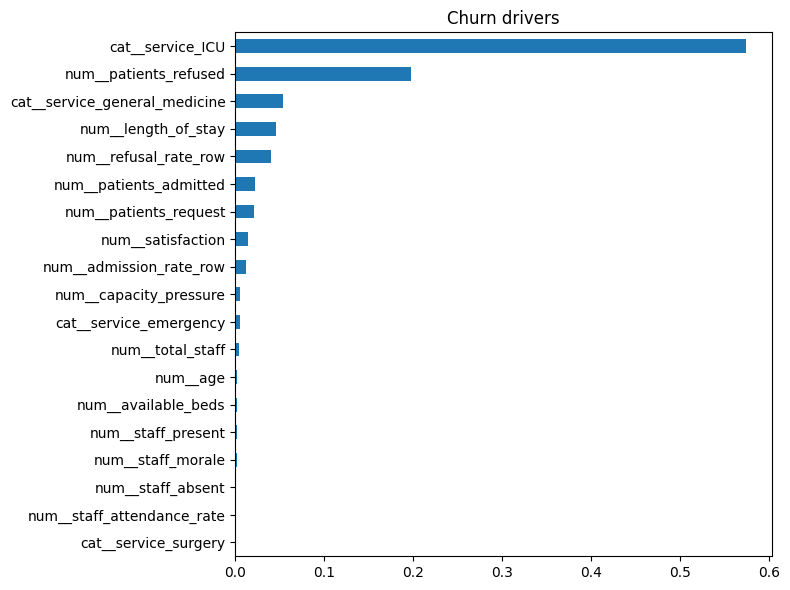

In [11]:
# Note: `best_pred_churn` is leakage (it's a prior prediction). Drop it.
CHURN_FEATURES = ["age","satisfaction","length_of_stay","available_beds",
                  "patients_request","patients_admitted","patients_refused",
                  "staff_morale","staff_present","total_staff","staff_absent",
                  "capacity_pressure","admission_rate_row","refusal_rate_row",
                  "staff_attendance_rate","service"]

X = df[CHURN_FEATURES].copy()
y = df["patient_churn"].astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

pre, _, _ = build_preprocessor(X_tr)

churn_model = Pipeline([
    ("pre", pre),
    ("clf", XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6,
                          subsample=0.9, colsample_bytree=0.9,
                          scale_pos_weight=(y_tr==0).sum()/max((y_tr==1).sum(),1),
                          eval_metric="logloss",
                          random_state=42, tree_method="hist"))
])
churn_model.fit(X_tr, y_tr)

y_pred = churn_model.predict(X_te)
y_prob = churn_model.predict_proba(X_te)[:,1]
print(evaluate_classifier("XGB Churn", y_te, y_pred, y_prob))
print(classification_report(y_te, y_pred, target_names=["Retained","Churned"]))

# Feature importance
oh_names = churn_model.named_steps["pre"].get_feature_names_out()
imp = pd.Series(churn_model.named_steps["clf"].feature_importances_,
                index=oh_names).sort_values(ascending=False).head(20)
plt.figure(figsize=(8,6))
imp[::-1].plot.barh()
plt.title("Churn drivers")
plt.tight_layout()
plt.show()

In [12]:
churn_model.named_steps["pre"].get_feature_names_out()

array(['num__age', 'num__satisfaction', 'num__length_of_stay',
       'num__available_beds', 'num__patients_request',
       'num__patients_admitted', 'num__patients_refused',
       'num__staff_morale', 'num__staff_present', 'num__total_staff',
       'num__staff_absent', 'num__capacity_pressure',
       'num__admission_rate_row', 'num__refusal_rate_row',
       'num__staff_attendance_rate', 'cat__service_ICU',
       'cat__service_emergency', 'cat__service_general_medicine',
       'cat__service_surgery'], dtype=object)

In [13]:
df.head()

,patient_id,name,age,arrival_date,departure_date,service,satisfaction,month,week,available_beds,patients_request,patients_admitted,patients_refused,patient_satisfaction,staff_morale,total_staff,staff_present,staff_absens,length_of_stay,patient_churn,best_pred_churn,age_bin,staff_absent,arrival_year,arrival_month,arrival_week,arrival_dow,is_weekend,capacity_pressure,capacity_pressure_level,admission_rate_row,refusal_rate_row,staff_attendance_rate,_dissat,_los_risk,_refusal_pressure,_morale_risk,risk_score,risk_level,health_score,flag_refused_gt_request,flag_present_gt_total,flag_absent_total_mismatch,flag_departure_before,flag_negative_los,flag_zero_request,integrity_flag_count,integrity_flagged,iso_anomaly,iso_score,iso_flag
0,PAT-09484753,Richard Rodriguez,24,2025-03-16,2025-03-22,surgery,61,3,3,27,66.0,27.0,39.0,63.0,72.0,25,0.0,25.0,6,1,1,19-35,25.0,2025,3,11,6,1,2.357143,High,0.409091,0.590909,0.000000,0.39,0.384615,0.590909,0.28,41.233566,Medium,74.355371,0,0,False,0,0,0,0,0,1,0.478683,0
1,PAT-f0644084,Shannon Walker,6,2025-12-13,2025-12-14,surgery,83,12,2,40,26.0,26.0,0.0,96.0,56.0,25,23.0,2.0,1,0,0,0-18,2.0,2025,12,50,5,1,0.634146,Low,1.000000,0.000000,0.920000,0.17,0.000000,0.000000,0.44,13.400000,Low,74.355371,0,0,False,0,0,0,0,0,1,0.480643,0
2,PAT-ac6162e4,Julia Torres,24,2025-06-29,2025-07-05,general_medicine,83,6,5,40,103.0,40.0,63.0,73.0,52.0,28,23.0,5.0,6,1,1,19-35,5.0,2025,6,26,6,1,2.512195,High,0.388350,0.611650,0.821429,0.17,0.384615,0.611650,0.48,35.848394,Medium,52.384121,0,0,False,0,0,0,0,0,1,0.427040,0
3,PAT-3dda2bb5,Crystal Johnson,32,2025-10-12,2025-10-23,emergency,81,10,2,28,169.0,28.0,141.0,75.0,64.0,39,37.0,2.0,11,1,1,19-35,2.0,2025,10,41,6,1,5.827586,Critical,0.165680,0.834320,0.948718,0.19,0.769231,0.834320,0.36,48.917160,Medium,48.986184,0,0,False,0,0,0,0,0,1,0.448562,0
4,PAT-08591375,Garrett Lin,25,2025-02-18,2025-02-25,ICU,76,2,3,20,21.0,20.0,1.0,82.0,89.0,34,0.0,34.0,7,0,0,19-35,34.0,2025,2,8,1,0,1.000000,Low,0.952381,0.047619,0.000000,0.24,0.461538,0.047619,0.11,23.740842,Low,106.574244,0,0,False,0,0,0,0,0,1,0.469679,0
